In [192]:
import torch
from matplotlib import pyplot as plt
import numpy as np
import lightning as L
from collections import Counter
import torchaudio

from murenn import MuReNNDirect,DTCWT,IDTCWT


In [193]:
HYPERPARAMS = {
    "sr": 16000,
    "seg_length": 1024,
    "win_length": 400,
    "n_mels": 5,
    "f_min": 4000,
    "f_max": 8000,
    "hop_length": 256,
    "n_samples": 5000,
}
mel_params = {
            "sample_rate": HYPERPARAMS["sr"],
            "n_fft": 1024,
            "win_length": HYPERPARAMS["win_length"],
            "hop_length": HYPERPARAMS["hop_length"],
            "f_min": HYPERPARAMS["f_min"],
            "f_max": HYPERPARAMS["f_max"],
            "n_mels": HYPERPARAMS["n_mels"],
            "center": False,
            "power": 2.0
        }
col = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
teacher = torchaudio.transforms.MelSpectrogram(**mel_params)
mel_fbank = teacher.mel_scale.fb.flip(dims=(-1,))

In [194]:
class Student(L.LightningModule):
    def __init__(self, spec):
        super().__init__()
        self.spec = spec
        self.train_outputs = []
        self.test_outputs = []
        self.val_outputs = []
        self.loss = torch.nn.MSELoss()

    def step(self, batch, fold):
        feat = batch[2]
        x = batch[1]
        Sx = self.forward(x)
        n_feat = feat.shape[-1]
        n_pred = Sx.shape[-1]
        N = min(n_feat, n_pred)
        loss = self.loss(Sx, feat)
        if fold == "train":
            self.train_outputs.append(loss)
        elif fold == "test":
            self.test_outputs.append(loss)
        elif fold == "val":
            self.val_outputs.append(loss)
        return {'loss': loss}

    def get_imp_fig(self, x):
        fig = plt.figure()
        conv1d = self.tfm.to_conv1d
        path_idx = 0
        paths = conv1d(x)#.flip(dims=(-2,))
        for j in range(self.J_psi):
            for q in range(self.Q[j]):
                path = paths[0, path_idx, :]
                path_hat = torch.fft.fft(path, axis=-1)
                plt.plot(torch.abs(path_hat).cpu(), color=col[j])
                path_idx +=1
        return fig

    def training_step(self, batch, batch_idx):
        return self.step(batch, "train")
    
    def validation_step(self, batch, batch_idx):
        return self.step(batch, "val")

    def test_step(self, batch, batch_idx):
        return self.step(batch, "test")
    
    def on_train_epoch_start(self):
        self.train_outputs = []
        self.test_outputs = []
        self.val_outputs = []

    def on_train_epoch_end(self):
        avg_loss = torch.tensor(self.train_outputs).mean()
        self.log('train_loss', avg_loss, prog_bar=False)
    
    def on_test_epoch_end(self):
        avg_loss = torch.tensor(self.test_outputs).mean()
        self.log('test_loss', avg_loss, prog_bar=False)

    def on_validation_epoch_end(self):
        avg_loss = torch.tensor(self.val_outputs).mean()
        x =torch.zeros(1,1,self.spec["seg_length"], device='mps')
        x[:,:,x.shape[-1]//2] = 1
        fig = self.get_imp_fig(x)
        tensorboard = self.logger.experiment
        tensorboard.add_figure("imp response", fig, global_step = self.trainer.global_step)
        tensorboard.close()
        self.log('val_loss', avg_loss, prog_bar=False)

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters())

In [195]:
class MuReNN(Student):
    def __init__(self, spec, Q_multiplier=16):
        super().__init__(spec)
        self.J_psi = spec["n_octave"]
        self.Q = spec["octaves"]
        self.tfm = MuReNNDirect(
            J = self.J_psi,
            Q = self.Q,
            T = Q_multiplier,
            in_channels = 1,
        )
        phi_kernel_size = teacher.n_fft // (2**self.J_psi) #dilation=2**J-->total kernel size = n_fft
        self.phi = torch.nn.Conv1d(
            in_channels=teacher.n_mels,
            out_channels=teacher.n_mels,
            kernel_size=phi_kernel_size,
            stride=teacher.hop_length // (2**self.J_psi), #total stride = 2**J*(hop_length)/(2**J)=hop length
            groups=teacher.n_mels,
            bias=False)

    def forward(self, x):
        x = x.reshape(x.shape[0],1,-1)
        x_levels = self.tfm(x)
        x_levels = x_levels.reshape(x_levels.shape[0],x_levels.shape[2],-1).flip(dims=(-2,)) # B, J*Q, T
        Sx = self.phi(x_levels)
        return Sx

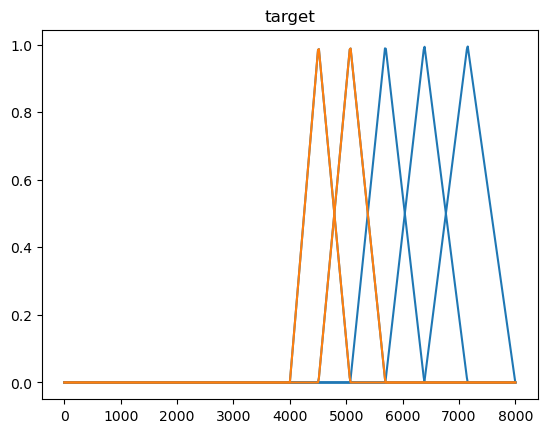

In [201]:
mel_scale = "htk"
# set x axis scale
m_min = torchaudio.functional.functional._hz_to_mel(
    teacher.f_min, mel_scale=mel_scale)
m_max = torchaudio.functional.functional._hz_to_mel(
    teacher.f_max, mel_scale=mel_scale)
# in mel scale
m_pts = torch.linspace(m_min, m_max, teacher.n_mels + 2)
# in freq(Hz) scale
f_pts = torchaudio.functional.functional._mel_to_hz(
    m_pts, mel_scale=mel_scale)
center_freqs = f_pts[1:-1]
nyquist = teacher.sample_rate // 2
octaves = np.around(np.log2(
    nyquist / center_freqs.numpy())).astype("int") # Nyquist/2**(j+2)<epsilon_j<Nyquist/2**(j+1), with j>=0 -->log_2^(Nyquist/epsilon_j)-2<j<log_2^(Nyquist/epsilon_j)-1
Q_ctr = Counter(octaves)
J_psi = max(Q_ctr)+1
boundaries = [0] + list(np.cumsum([Q_ctr[j] for j in range(J_psi)])) + [len(octaves)]
omega = np.linspace(0, nyquist, mel_fbank.shape[0], endpoint=True)
for j in range(J_psi):
    psi_octave = mel_fbank[:, boundaries[j]:boundaries[j+2]]
    plt.plot(omega, psi_octave, color=col[j]);
plt.title("target")

HYPERPARAMS["n_octave"] = J_psi
HYPERPARAMS["octaves"] = Q_ctr

In [197]:
ckpt_pth = "/Users/zhang/MuReNN/murenn_theory/reproduce_waspaa/chpt/synth/0/last-v1.ckpt"
M = MuReNN.load_from_checkpoint(ckpt_pth,spec=HYPERPARAMS)
M.eval()
M.to('cpu')
FIRs = M.tfm.conv1d
N = 1024
x = torch.zeros(1,1,N)
x[:,:,N//2] = 1
omega = torch.linspace(0, HYPERPARAMS['sr'], N)

In [205]:
ckpt_pth = "/Users/zhang/MuReNN/murenn_theory/reproduce_waspaa/chpt/synth/0/last-v1.ckpt"
M = MuReNN.load_from_checkpoint(ckpt_pth,spec=HYPERPARAMS)
M.eval()
M.to('cpu')
FIRs = M.tfm.conv1d
N = 16000
x = torch.zeros(1,1,N)
x[:,:,N//2] = 1
omega = torch.linspace(0, HYPERPARAMS['sr'], N)
dtcwt = DTCWT(J=HYPERPARAMS["n_octave"],alternate_gh=False)
idtcwt = IDTCWT(J=HYPERPARAMS["n_octave"],alternate_gh=False)
phi, psis = dtcwt(x)
x_psis = []
x_phi = phi * 0
for j, psi in enumerate(psis):
    x_psis_j = []
    for q in range(FIRs[j].out_channels):
        psi_r = FIRs[j](psi.real)[:, q, :].unsqueeze(1)
        psi_i = FIRs[j](psi.imag)[:, q, :].unsqueeze(1)
        x_psis_q = [psi * 0 if k != j else torch.complex(psi_r, psi_i) for k, psi in enumerate(psis)]
        x_rec_q = idtcwt(x_phi, x_psis_q)
        x_psis_j.append(x_rec_q)
    x_psis_j = torch.stack(x_psis_j, dim=0).squeeze()
    x_psis.append(x_psis_j)

j_psis = [psi * 0 if j != 1 else psi for j, psi in enumerate(psis)]
psi_rec = idtcwt(x_phi, j_psis)

tensor(1.0000)

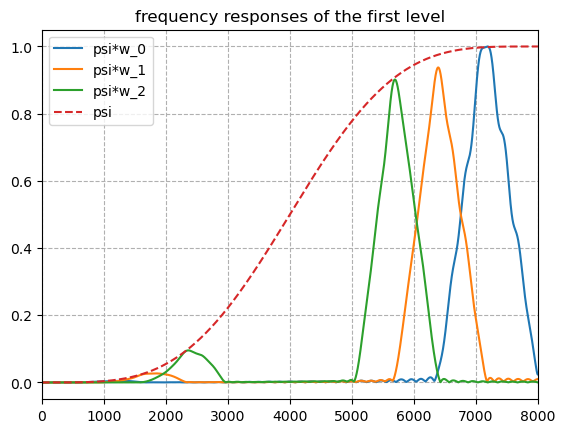

In [203]:
J = 0
x_j = x_psis[J]
j_psis = [psi * 0 if j != J else psi for j, psi in enumerate(psis)]
psi_rec = idtcwt(x_phi, j_psis)
for q in range(x_j.shape[0]):
    x_q_hat = torch.fft.fft(x_j, dim=-1).squeeze().detach()
    scale_factor = torch.max(x_q_hat.abs())
    plt.plot(x_q_hat[q].abs()/scale_factor,label=f'psi*w_{q}')
plt.plot(torch.fft.fft(psi_rec).abs().squeeze().detach()/torch.max(torch.fft.fft(psi_rec).abs().squeeze().detach()), label='psi', linestyle='--')
plt.legend()
plt.grid(linestyle='--')
plt.xlim(0, 8000)
plt.legend()
plt.title('frequency responses of the first level')
torch.max(torch.fft.fft(psi_rec).abs().squeeze().detach())

tensor(0.7955)

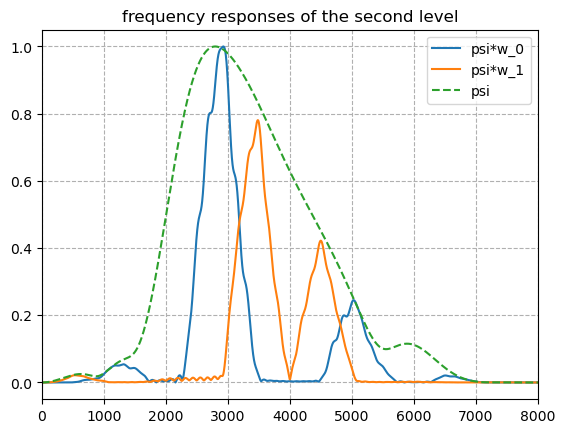

In [204]:
J = 1
x_j = x_psis[J]
j_psis = [psi * 0 if j != J else psi for j, psi in enumerate(psis)]
psi_rec = idtcwt(x_phi, j_psis)
for q in range(x_j.shape[0]):
    x_q_hat = torch.fft.fft(x_j, dim=-1).squeeze().detach()
    scale_factor = torch.max(x_q_hat.abs())
    plt.plot(x_q_hat[q].abs()/scale_factor,label=f'psi*w_{q}')
plt.plot(torch.fft.fft(psi_rec).abs().squeeze().detach()/torch.max(torch.fft.fft(psi_rec).abs().squeeze().detach()), label='psi', linestyle='--')
plt.legend()
plt.grid(linestyle='--')
plt.xlim(0, 8000)
plt.legend()
plt.title('frequency responses of the second level')
torch.max(torch.fft.fft(psi_rec).abs().squeeze().detach())

but i can set the left part to 0 for visualization

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Text(0.5, 1.0, 'MuReNN after training')

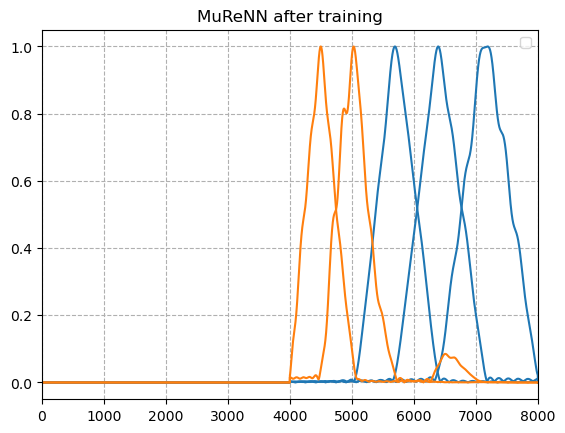

In [218]:
for J in range(J_psi):
    x_j = x_psis[J]
    for q in range(x_j.shape[0]):
        x_q_hat = torch.fft.fft(x_j, dim=-1).squeeze().detach().abs()
        x_q_hat[:, :N//4] = 0
        x_q_hat[:, N//2:] = 0
        plt.plot(x_q_hat[q,:]/torch.max(x_q_hat[q,:]),color=col[J])
plt.legend()
plt.grid(linestyle='--')
plt.xlim(0, 8000)
plt.title('MuReNN after training')